# Analisi S-value — decadimento del Cu-64 nel nucleo cellulare

Notebook per aggregare i batch della simulazione Geant4 (`S-value`) e ricavare:
- l'S-value combinato per citoplasma, nucleo e **intera cellula** (nucleo + citoplasma), con errore statistico corretto sulla media;
- la distribuzione $f_1(z_n)$ dell'energia specifica per singolo decadimento nel nucleo (istogramma 6), utile per il modello LQ e come punto di partenza per il modello MK;
- un controllo incrociato tra i valori riportati nei file `s_batchNN.txt` e quelli ricalcolati dagli istogrammi nei file `.root`.

**Nota importante.** I file `s_batchNN.txt` sono aperti in modalità *append* (`Run::EndOfRun`, `fopen(..., "a")`): se un batch è stato eseguito più volte, il file contiene più righe. I file `.root`, invece, vengono sovrascritti a ogni esecuzione (`analysisManager->OpenFile()` di default). Per coerenza, da ogni `.txt` viene quindi usata **solo l'ultima riga**, corrispondente al contenuto attuale del `.root`.

**Limite noto.** Gli istogrammi qui disponibili danno $f_1(z_n)$ sull'intero nucleo, sufficiente per il modello LQ e per l'S-value. Il modello MK richiederebbe $f_1(z)$ in domini sub-nucleari di raggio $r_d \ll R_n$: non essendo disponibile uno scoring per posizione, in questo notebook si userà come approssimazione $r_d = R_n$ (dominio = intero nucleo), da sostituire quando sarà disponibile uno scoring posizionale.

## 1. Setup


In [1]:
import glob
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

# Cartella con i file di output (adattare se necessario)
BUILD_DIR = Path("../build")

root_files = sorted(BUILD_DIR.glob("cu64_batch*.root"))
txt_files  = sorted(BUILD_DIR.glob("s_batch*.txt"))

print(f"Trovati {len(root_files)} file .root e {len(txt_files)} file .txt")
for f in root_files:
    print(" ", f.name)


Trovati 10 file .root e 10 file .txt
  cu64_batch01.root
  cu64_batch02.root
  cu64_batch03.root
  cu64_batch04.root
  cu64_batch05.root
  cu64_batch06.root
  cu64_batch07.root
  cu64_batch08.root
  cu64_batch09.root
  cu64_batch10.root


## 2. Lettura dei file `.txt` (ultima riga per batch)

Colonne, nell'ordine scritto da `Run::EndOfRun()` (9 colonne):

```
R_nucleo[nm]  spessore_citoplasma[nm]  E_cin_primario[eV]  S_cito  err_S_cito  S_nucl  err_S_nucl  S_cell  err_S_cell
```

Gli S-value sono in mGy/Bq·s. Gli `err_*` sono l'**errore standard della media** sul singolo batch (`sigma/sqrt(N)`, calcolato in `EndOfRun`), non la deviazione standard della distribuzione a singolo decadimento.

`S_cell` è l'S-value dell'intera cellula, $(E_\mathrm{cito}+E_\mathrm{nucl})/(M_\mathrm{cito}+M_\mathrm{nucl})$. Il suo errore è calcolato dalla somma citoplasma + nucleo **evento per evento**, quindi tiene conto della correlazione tra i due depositi e non va ricavato dagli errori degli altri due.

I file prodotti prima dell'aggiunta della cellula intera hanno righe a 7 colonne: vengono lette con `NaN` nelle ultime due colonne. Poiché si usa solo l'ultima riga, conta solo che questa sia nel nuovo formato.

In [2]:
TXT_COLS = [
    "R_nucl_nm", "cyto_thick_nm", "Ekin_eV",
    "S_cyto_mGy_Bqs", "sigma_S_cyto",
    "S_nucl_mGy_Bqs", "sigma_S_nucl",
    "S_cell_mGy_Bqs", "sigma_S_cell",
]

def batch_id_from_name(path, pattern):
    m = re.search(pattern, path.name)
    return m.group(1) if m else path.stem

txt_rows = {}
n_lines_per_batch = {}

for f in txt_files:
    bid = batch_id_from_name(f, r"s_(batch\d+)")
    # 9 nomi di colonna: le vecchie righe a 7 colonne vengono lette con NaN in coda
    df = pd.read_csv(f, sep=r"\s+", header=None, names=TXT_COLS)
    n_lines_per_batch[bid] = len(df)
    txt_rows[bid] = df.iloc[-1]  # solo l'ultima riga: corrisponde al .root attuale

txt_summary = pd.DataFrame(txt_rows).T
txt_summary.index.name = "batch"
txt_summary["n_run_lines"] = pd.Series(n_lines_per_batch)

old_format = txt_summary.index[txt_summary["S_cell_mGy_Bqs"].isna()].tolist()
if old_format:
    print("ATTENZIONE: l'ultima riga di questi batch è ancora nel vecchio formato a 7 colonne:", old_format)

print("Numero di righe (= numero di esecuzioni) per ciascun batch:")
print(txt_summary["n_run_lines"])
print()
txt_summary

Numero di righe (= numero di esecuzioni) per ciascun batch:
batch
batch01    1
batch02    1
batch03    1
batch04    1
batch05    1
batch06    1
batch07    1
batch08    1
batch09    1
batch10    1
Name: n_run_lines, dtype: int64



,R_nucl_nm,cyto_thick_nm,Ekin_eV,S_cyto_mGy_Bqs,sigma_S_cyto,S_nucl_mGy_Bqs,sigma_S_nucl,S_cell_mGy_Bqs,sigma_S_cell,n_run_lines
batch,,,,,,,,,,
batch01,4000.0,1000.0,0.0,0.759740,0.004449,0.936372,0.005210,0.850176,0.003247,1
batch02,4000.0,1000.0,0.0,0.764687,0.004470,0.929013,0.005199,0.848822,0.003258,1
batch03,4000.0,1000.0,0.0,0.761538,0.004463,0.939787,0.005243,0.852801,0.003269,1
batch04,4000.0,1000.0,0.0,0.757620,0.004440,0.932484,0.005221,0.847150,0.003245,1
batch05,4000.0,1000.0,0.0,0.763432,0.004465,0.934491,0.005234,0.851014,0.003263,1
batch06,4000.0,1000.0,0.0,0.763903,0.004478,0.935717,0.005227,0.851872,0.003259,1
batch07,4000.0,1000.0,0.0,0.772616,0.004491,0.934921,0.005234,0.855716,0.003267,1
batch08,4000.0,1000.0,0.0,0.758812,0.004445,0.929535,0.005201,0.846222,0.003249,1
batch09,4000.0,1000.0,0.0,0.762109,0.004448,0.928850,0.005216,0.847480,0.003261,1


Se qualche batch ha più di una riga, vale la pena controllare a mano se le righe scartate sono davvero duplicati/test falliti, o se contengono statistica che vorresti recuperare (nel qual caso il seed andrebbe randomizzato e i run rilanciati).


## 2b. S-value di citoplasma, nucleo e intera cellula: controllo di coerenza

L'S-value della cellula intera è la media degli altri due pesata sulle masse:

$$S_\mathrm{cell} = \frac{M_\mathrm{cito}\,S_\mathrm{cito} + M_\mathrm{nucl}\,S_\mathrm{nucl}}{M_\mathrm{cito}+M_\mathrm{nucl}}$$

Poiché nucleo e citoplasma hanno la stessa densità (acqua), i pesi sono i volumi: sfera di raggio $R$ per il nucleo e guscio sferico di spessore $t$ per il citoplasma. Il confronto con `S_cell` del `.txt` deve tornare entro la precisione di stampa (differenze relative dell'ordine di $10^{-5}$ % o meno). Una differenza maggiore indica una massa sbagliata o un deposito contato due volte. Se le densità dei due volumi fossero diverse, i pesi sarebbero $\rho V$.

In [3]:
txt_num = txt_summary.drop(columns=["n_run_lines"]).astype(float)

R = txt_num["R_nucl_nm"]
t = txt_num["cyto_thick_nm"]
V_nucl = 4.0 / 3.0 * np.pi * R**3
V_cyto = 4.0 / 3.0 * np.pi * ((R + t)**3 - R**3)

S_cell_atteso = (V_cyto * txt_num["S_cyto_mGy_Bqs"] + V_nucl * txt_num["S_nucl_mGy_Bqs"]) / (V_cyto + V_nucl)

check = pd.DataFrame({
    "S_cyto": txt_num["S_cyto_mGy_Bqs"],
    "S_nucl": txt_num["S_nucl_mGy_Bqs"],
    "S_cell_txt": txt_num["S_cell_mGy_Bqs"],
    "S_cell_atteso_da_masse": S_cell_atteso,
})
check["diff_%"] = 100 * (check["S_cell_txt"] - check["S_cell_atteso_da_masse"]) / check["S_cell_atteso_da_masse"]
check

,S_cyto,S_nucl,S_cell_txt,S_cell_atteso_da_masse,diff_%
batch,,,,,
batch01,0.759740,0.936372,0.850176,0.850176,-0.000005
batch02,0.764687,0.929013,0.848822,0.848822,-0.000001
batch03,0.761538,0.939787,0.852801,0.852801,-0.000004
batch04,0.757620,0.932484,0.847150,0.847150,0.000005
batch05,0.763432,0.934491,0.851014,0.851014,-0.000002
batch06,0.763903,0.935717,0.851872,0.851872,0.000004
batch07,0.772616,0.934921,0.855716,0.855716,-0.000006
batch08,0.758812,0.929535,0.846222,0.846222,0.000003
batch09,0.762109,0.928850,0.847480,0.847480,-0.000005


## 3. Lettura dei file `.root`

Gli istogrammi sono `TH1D` con ID fissi:

| ID | Contenuto |
|----|-----------|
| 0  | energia cinetica e- Auger |
| 1  | energia cinetica e- Auger a bassa energia |
| 5  | energia depositata nel citoplasma |
| 6  | energia depositata nel nucleo |
| 7  | lunghezza di traccia della primaria |
| 10 | lunghezza di traccia dei secondari carichi |

Qui usiamo l'istogramma **6** (nucleo), che è quello rilevante per l'S-value e per $f_1(z_n)$.


In [4]:
NUCL_HIST_ID = "6"

def read_hist(root_path, hist_id):
    with uproot.open(root_path) as f:
        h = f[f"{hist_id};1"]
        counts, edges = h.to_numpy()
        return counts, edges

batch_hists = {}   # bid -> (counts, edges)
batch_n_events = {}  # bid -> numero di eventi (somma dei conteggi dell'istogramma)

for f in root_files:
    bid = batch_id_from_name(f, r"cu64_(batch\d+)")
    counts, edges = read_hist(f, NUCL_HIST_ID)
    batch_hists[bid] = (counts, edges)
    batch_n_events[bid] = counts.sum()

n_events_summary = pd.Series(batch_n_events, name="N_eventi_da_istogramma")
n_events_summary.index.name = "batch"
n_events_summary


batch
batch01    61573.0
batch02    61432.0
batch03    61495.0
batch04    61451.0
batch05    61247.0
batch06    61588.0
batch07    61530.0
batch08    61492.0
batch09    61480.0
batch10    61564.0
Name: N_eventi_da_istogramma, dtype: float64

**Controllo:** se `N_eventi_da_istogramma` non è uguale per tutti i batch, vuol dire che sono stati lanciati con statistiche diverse (va bene, ma la combinazione qui sotto ne tiene conto pesando per $N$); se invece tutti i bin sono a zero per qualche batch, quel `.root` va controllato a parte (probabile run vuoto o fallito).


## 4. S-value per batch: media e deviazione standard dall'istogramma

Ricalcoliamo media e sigma della distribuzione a singolo decadimento direttamente dall'istogramma, per confronto con i valori riportati nel `.txt`. Nota: qui l'energia è in **keV** (bin edges 0–700 keV secondo il binning dichiarato); adattare `EDEP_UNIT_keV` se nel tuo `EventAction` usi un'altra unità di conversione per `FillH1`.


In [5]:
EDEP_UNIT_keV = 1.0  # se FillH1(6, edep/keV) -> 1.0; se invece è edep/MeV -> cambiare qui

def hist_mean_std(counts, edges):
    centers = 0.5 * (edges[:-1] + edges[1:])
    n = counts.sum()
    if n == 0:
        return 0.0, 0.0, 0
    mean = np.sum(counts * centers) / n
    var = np.sum(counts * centers**2) / n - mean**2
    std = np.sqrt(var) if var > 0 else 0.0
    return mean * EDEP_UNIT_keV, std * EDEP_UNIT_keV, int(n)

hist_summary = {}
for bid, (counts, edges) in batch_hists.items():
    mean_keV, std_keV, n = hist_mean_std(counts, edges)
    hist_summary[bid] = {"mean_edep_keV": mean_keV, "sigma_edep_keV": std_keV, "N_eventi": n}

hist_summary = pd.DataFrame(hist_summary).T
hist_summary.index.name = "batch"
hist_summary


,mean_edep_keV,sigma_edep_keV,N_eventi
batch,,,
batch01,2.599703,3.174725,61573.0
batch02,2.584126,3.172934,61432.0
batch03,2.612448,3.196793,61495.0
batch04,2.594693,3.185161,61451.0
batch05,2.610487,3.194541,61247.0
batch06,2.597324,3.187451,61588.0
batch07,2.598407,3.193518,61530.0
batch08,2.586092,3.173070,61492.0
batch09,2.583767,3.184264,61480.0


## 5. Massa del nucleo e conversione in S-value (Gy/decadimento)

Nucleo modellato come sfera d'acqua di raggio `R_nucl_nm` (dal `.txt`). Se nel tuo `DetectorConstruction` la geometria è diversa (es. non è una sfera, o la densità non è quella dell'acqua), **aggiorna questa cella** di conseguenza.


In [6]:
RHO_WATER_kg_m3 = 1000.0

def nucleus_mass_kg(R_nm):
    R_m = R_nm * 1e-9
    volume_m3 = (4.0 / 3.0) * np.pi * R_m**3
    return RHO_WATER_kg_m3 * volume_m3

# Raggio nucleo: assunto uguale per tutti i batch, preso dal primo txt disponibile
R_nucl_nm = txt_summary["R_nucl_nm"].iloc[0]
if not np.allclose(txt_summary["R_nucl_nm"], R_nucl_nm):
    print("ATTENZIONE: i batch non hanno tutti lo stesso raggio del nucleo!")
    print(txt_summary["R_nucl_nm"])

m_nucl_kg = nucleus_mass_kg(R_nucl_nm)
print(f"Raggio nucleo: {R_nucl_nm} nm  ->  massa nucleo: {m_nucl_kg:.4e} kg")

# Conversione energia depositata (keV) -> dose (Gy) per decadimento
keV_to_J = 1.602176634e-16

hist_summary["S_nucl_from_hist_Gy_per_decay"] = (
    hist_summary["mean_edep_keV"] * keV_to_J / m_nucl_kg
)
hist_summary["sigma_S_nucl_from_hist_Gy_per_decay"] = (
    hist_summary["sigma_edep_keV"] * keV_to_J / m_nucl_kg
)
hist_summary


Raggio nucleo: 4000.0 nm  ->  massa nucleo: 2.6808e-13 kg


,mean_edep_keV,sigma_edep_keV,N_eventi,S_nucl_from_hist_Gy_per_decay,sigma_S_nucl_from_hist_Gy_per_decay
batch,,,,,
batch01,2.599703,3.174725,61573.0,0.001554,0.001897
batch02,2.584126,3.172934,61432.0,0.001544,0.001896
batch03,2.612448,3.196793,61495.0,0.001561,0.001911
batch04,2.594693,3.185161,61451.0,0.001551,0.001904
batch05,2.610487,3.194541,61247.0,0.001560,0.001909
batch06,2.597324,3.187451,61588.0,0.001552,0.001905
batch07,2.598407,3.193518,61530.0,0.001553,0.001909
batch08,2.586092,3.173070,61492.0,0.001546,0.001896
batch09,2.583767,3.184264,61480.0,0.001544,0.001903


## 6. Confronto tra `.txt` e `.root`

Confrontiamo `S_nucl` riportato nel `.txt` (già in mGy/Bq·s, quindi da dividere per 1000 per avere Gy) con `S_nucl_from_hist_Gy_per_decay` ricalcolato qui sopra. Se i due non coincidono (a meno di piccole differenze numeriche), va ricontrollata l'unità usata in `FillH1(6, ...)` (parametro `EDEP_UNIT_keV` sopra) o la definizione di massa del nucleo in `DetectorConstruction`.


In [7]:
comparison = pd.DataFrame({
    "S_nucl_txt_Gy_per_decay": txt_summary["S_nucl_mGy_Bqs"].astype(float) / 1000.0,
    "S_nucl_hist_Gy_per_decay": hist_summary["S_nucl_from_hist_Gy_per_decay"],
})
comparison["rel_diff_%"] = 100 * (comparison["S_nucl_hist_Gy_per_decay"]
                                   - comparison["S_nucl_txt_Gy_per_decay"]) / comparison["S_nucl_txt_Gy_per_decay"]
comparison


,S_nucl_txt_Gy_per_decay,S_nucl_hist_Gy_per_decay,rel_diff_%
batch,,,
batch01,0.000936,0.001554,65.926941
batch02,0.000929,0.001544,66.239361
batch03,0.000940,0.001561,66.134641
batch04,0.000932,0.001551,66.297854
batch05,0.000934,0.001560,66.950659
batch06,0.000936,0.001552,65.891272
batch07,0.000935,0.001553,66.101770
batch08,0.000930,0.001546,66.272453
batch09,0.000929,0.001544,66.245362


## 7. Combinazione dei 10 batch

Media pesata sui decadimenti totali (non media semplice dei batch), con errore statistico sulla media (deviazione standard della distribuzione a singolo decadimento, divisa per $\sqrt{N_\mathrm{tot}}$) e, separatamente, la dispersione batch-a-batch come stima della sistematica tra run.


In [8]:
N = hist_summary["N_eventi"].astype(float)
S = hist_summary["S_nucl_from_hist_Gy_per_decay"]
sigma = hist_summary["sigma_S_nucl_from_hist_Gy_per_decay"]

N_tot = N.sum()

# Media pesata sui decadimenti totali (equivalente a sommare tutti gli eventi insieme)
S_combined = np.sum(N * S) / N_tot

# Errore statistico sulla media: sigma della distribuzione singolo-decadimento / sqrt(N_tot)
# Si combina la sigma per-batch pesata sugli eventi
sigma_pooled = np.sqrt(np.sum(N * sigma**2) / N_tot)
err_stat = sigma_pooled / np.sqrt(N_tot)

# Dispersione batch-a-batch (sistematica tra run), solo se piu' di un batch
S_per_batch = S.values
std_between_batches = S_per_batch.std(ddof=1) if len(S_per_batch) > 1 else 0.0

print(f"Numero totale di decadimenti simulati: {N_tot:.0f}")
print(f"S-value nucleo combinato:        {S_combined:.4e} Gy/decadimento")
print(f"Errore statistico sulla media:    {err_stat:.4e} Gy/decadimento")
print(f"Dispersione batch-a-batch (std):  {std_between_batches:.4e} Gy/decadimento")


Numero totale di decadimenti simulati: 614852
S-value nucleo combinato:        1.5521e-03 Gy/decadimento
Errore statistico sulla media:    2.4293e-06 Gy/decadimento
Dispersione batch-a-batch (std):  6.0694e-06 Gy/decadimento


## 7b. S-value combinati di citoplasma, nucleo e intera cellula (da `.txt`)

Per i tre S-value si usano direttamente le colonne del `.txt`, che sono già medie su **tutti** gli eventi del batch (anche quelli senza deposito) e, per la cellula intera, hanno l'errore corretto per la correlazione cito-nucleo. Ipotesi: tutti i batch hanno lo stesso numero di eventi.

Per ogni S-value:
- `S_medio`: media dei batch;
- `err_stat`: errore sulla media dagli errori stampati per batch, $\sqrt{\sum_i \sigma_i^2}/n_\mathrm{batch}$;
- `std_batch`: deviazione standard dei valori tra batch, e `err_batch` $=\mathrm{std}/\sqrt{n_\mathrm{batch}}$;
- `chi2/dof`: confronto tra dispersione osservata e errori stampati. Deve essere vicino a 1: se è molto maggiore, gli errori per batch sono sottostimati (o c'è una differenza sistematica tra batch, ad esempio seed uguali o configurazioni diverse).

In [9]:
txt_num = txt_summary.drop(columns=["n_run_lines"]).astype(float)

targets = [
    ("citoplasma", "S_cyto_mGy_Bqs", "sigma_S_cyto"),
    ("nucleo",     "S_nucl_mGy_Bqs", "sigma_S_nucl"),
    ("cellula",    "S_cell_mGy_Bqs", "sigma_S_cell"),
]

rows = []
for name, col, err_col in targets:
    d = txt_num[[col, err_col]].dropna()
    vals, errs = d[col].values, d[err_col].values
    n = len(vals)
    mean = vals.mean()
    err_stat = np.sqrt(np.sum(errs**2)) / n
    std_batch = vals.std(ddof=1) if n > 1 else np.nan
    chi2_dof = np.sum((vals - mean)**2 / errs**2) / (n - 1) if n > 1 else np.nan
    rows.append({
        "bersaglio": name, "n_batch": n,
        "S_medio_mGy_Bqs": mean, "err_stat": err_stat,
        "std_batch": std_batch, "err_batch": std_batch / np.sqrt(n) if n > 1 else np.nan,
        "chi2/dof": chi2_dof,
    })

svalue_combined = pd.DataFrame(rows).set_index("bersaglio")
svalue_combined

,n_batch,S_medio_mGy_Bqs,err_stat,std_batch,err_batch,chi2/dof
bersaglio,,,,,,
citoplasma,10,0.762692,0.001410,0.004159,0.001315,0.864079
nucleo,10,0.933835,0.001652,0.003751,0.001186,0.515924
cellula,10,0.850317,0.001031,0.002942,0.000930,0.814719


## 8. Distribuzione combinata $f_1(z_n)$

Si sommano i conteggi dei 10 istogrammi (stesso binning) per ottenere la distribuzione a singolo decadimento con tutta la statistica disponibile, poi la si converte in energia specifica $z_n$ (Gy/decadimento) usando la massa del nucleo.


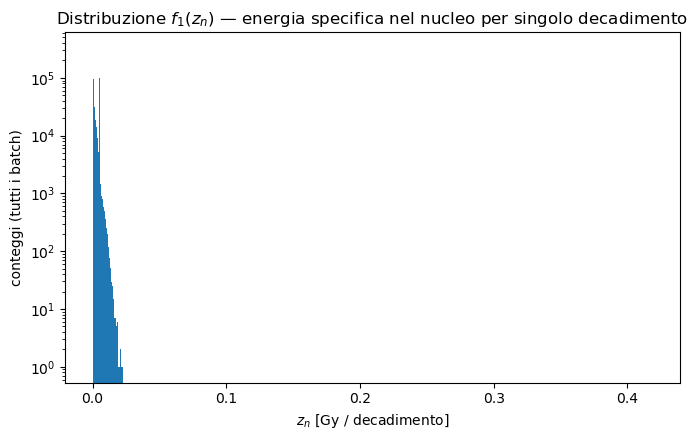

Eventi totali nell'istogramma combinato: 614852
Media della distribuzione combinata:      1.5521e-03 Gy/decadimento


In [10]:
# Verifica che tutti gli istogrammi abbiano lo stesso binning
edges_ref = None
counts_sum = None
for bid, (counts, edges) in batch_hists.items():
    if edges_ref is None:
        edges_ref = edges
        counts_sum = counts.copy().astype(float)
    else:
        if not np.allclose(edges, edges_ref):
            raise ValueError(f"Binning diverso nel batch {bid}: impossibile sommare direttamente.")
        counts_sum += counts

centers_keV = 0.5 * (edges_ref[:-1] + edges_ref[1:]) * EDEP_UNIT_keV
z_n_Gy = centers_keV * keV_to_J / m_nucl_kg

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(z_n_Gy, counts_sum, width=np.diff(z_n_Gy).mean(), align="center")
ax.set_xlabel(r"$z_n$ [Gy / decadimento]")
ax.set_ylabel("conteggi (tutti i batch)")
ax.set_title(r"Distribuzione $f_1(z_n)$ — energia specifica nel nucleo per singolo decadimento")
ax.set_yscale("log")
plt.tight_layout()
plt.show()

print(f"Eventi totali nell'istogramma combinato: {counts_sum.sum():.0f}")
print(f"Media della distribuzione combinata:      {np.sum(counts_sum * z_n_Gy) / counts_sum.sum():.4e} Gy/decadimento")


## 8b. Distribuzione dell'energia per l'intera cellula (opzionale)

Gli istogrammi 5 (citoplasma) e 6 (nucleo) non permettono di ricostruire la distribuzione della somma $E_\mathrm{cito}+E_\mathrm{nucl}$ per evento, perché la somma richiede di sapere quali depositi appartengono allo stesso evento. Serve un istogramma dedicato, riempito in `EventAction::EndOfEventAction` con `FillH1(<ID>, fCellEdep + fNuclEdep)` e creato in `HistoManager`. Usa un ID libero: nella tabella della sezione 3 gli ID 7 e 10 sono già occupati.

Una volta creato, imposta `CELL_HIST_ID` qui sotto. Finché è `None`, la cella viene saltata.

In [11]:
CELL_HIST_ID = None   # es. "11": ID dell'istogramma con E_cito + E_nucl per evento

def cytoplasm_mass_kg(R_nm, t_nm):
    R_m, Rt_m = R_nm * 1e-9, (R_nm + t_nm) * 1e-9
    return RHO_WATER_kg_m3 * (4.0 / 3.0) * np.pi * (Rt_m**3 - R_m**3)

if CELL_HIST_ID is None:
    print("Nessun istogramma dell'energia totale della cellula: sezione saltata.")
else:
    edges_c, counts_c = None, None
    for f in root_files:
        counts, edges = read_hist(f, CELL_HIST_ID)
        if edges_c is None:
            edges_c, counts_c = edges, counts.astype(float)
        else:
            if not np.allclose(edges, edges_c):
                raise ValueError(f"Binning diverso in {f.name}")
            counts_c += counts

    t_cyto_nm = float(txt_summary["cyto_thick_nm"].iloc[0])
    m_cell_kg = m_nucl_kg + cytoplasm_mass_kg(R_nucl_nm, t_cyto_nm)

    centers_c_keV = 0.5 * (edges_c[:-1] + edges_c[1:]) * EDEP_UNIT_keV
    z_cell_Gy = centers_c_keV * keV_to_J / m_cell_kg

    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.bar(z_cell_Gy, counts_c, width=np.diff(z_cell_Gy).mean(), align="center")
    ax.set_xlabel(r"$z_\mathrm{cell}$ [Gy / decadimento]")
    ax.set_ylabel("conteggi (tutti i batch)")
    ax.set_title("Energia specifica nell'intera cellula per singolo decadimento")
    ax.set_yscale("log")
    plt.tight_layout()
    plt.show()

    print(f"Eventi con deposito > 0: {counts_c.sum():.0f}")
    print("Nota: l'istogramma contiene solo gli eventi con deposito > 0, quindi la media qui sopra")
    print("non coincide con S_cell del .txt (media su tutti gli eventi) se esistono eventi senza deposito.")

Nessun istogramma dell'energia totale della cellula: sezione saltata.


## 9. Prossimi passi

- **Modello LQ**: con `S_combined` (S-value per decadimento) e il numero di decadimenti $\tilde N$, si ottiene $D = \tilde N \cdot S_\mathrm{combined}$ e quindi $S(D)$ dall'Eq. LQ del capitolo.
- **Modello MK**: la distribuzione qui ottenuta è $f_1(z_n)$ sull'**intero nucleo**, non nei domini sub-nucleari $r_d$. Per il vero calcolo MK serve uno scoring per posizione (es. un ntuple con posizione + energia di ogni deposito), da cui ricostruire $f_1(z)$ per domini sferici di raggio arbitrario in post-processing, come descritto nel capitolo. Finché non è disponibile, si può usare $r_d = R_n$ come approssimazione (dominio = nucleo), sapendo che sovrastima l'effetto di saturazione rispetto a domini più piccoli.
- **Numero di radionuclidi vs segnale PET**: una volta scelti $\alpha_0,\beta,y_0,r_d$ per la linea cellulare, si può invertire il modello come nella Sez. 3.7 del capitolo usando `S_combined` al posto di $\langle z_n\rangle$ calcolato da simulazioni a granularità di dominio.
